<a href="https://colab.research.google.com/github/zhiyuguo-innis/MSSP607/blob/main/Assignments/zhiyuguo_innis_Case_Study_Assignment3_Housing_Prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/zhiyuguo-innis/MSSP607/blob/main/Assignments/zhiyuguo_innis_Case_Study_Assignment3_Housing_Prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case 3: Sale Prices of Homes in Neighborhood ABC

**Student:** Zhiyu Guo · MSSP 607, University of Pennsylvania
**Dataset:** `HousingPrices.csv`, 1,460 home sales with 17 attributes, a subset of the Kaggle
*House Prices: Advanced Regression Techniques* data. Fictitious data, used for learning purposes only.

## 1. Setup

In [23]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats
import statsmodels.formula.api as smf

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

# Chart colours (colour-blind-safe categorical palette, same as Case 2)
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
GREY, GREY_TEXT, GRID = '#9b9a96', '#52514e', '#e5e5e2'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.edgecolor': GREY_TEXT, 'axes.labelcolor': GREY_TEXT,
                     'xtick.color': GREY_TEXT, 'ytick.color': GREY_TEXT,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'font.size': 10})
usd = FuncFormatter(lambda v, _: f'${v/1000:,.0f}K')
os.makedirs('figures', exist_ok=True)

The CSV is stored in my GitHub repository and read through its *raw* URL.

In [24]:
DATA_URL = 'https://raw.githubusercontent.com/zhiyuguo-innis/MSSP607/main/data/HousingPrices.csv'
LOCAL_COPY = 'HousingPrices.csv'   # only used if GitHub cannot be reached

try:
    homes = pd.read_csv(DATA_URL)
    print('Loaded from GitHub:', DATA_URL)
except Exception as err:
    print('GitHub read failed (', type(err).__name__, ') - reading local copy instead.')
    homes = pd.read_csv(LOCAL_COPY)

print('Shape:', homes.shape)
homes.head()

Loaded from GitHub: https://raw.githubusercontent.com/zhiyuguo-innis/MSSP607/main/data/HousingPrices.csv
Shape: (1460, 17)


,Id,LotFrontage,LotArea,HouseStyle,OverallQual,OverallCond,YearBuilt,TotalBsmtSF,CentralAir,1stFlrSF,2ndFlrSF,FullBath,TotalRooms,GarageCars,GarageArea,YrSold,SalePrice
0,1,65.00,"8,450.00",2Story,7,5,2003,856.00,Y,856,854,2,8,2,548,2008,208500
1,2,80.00,"9,600.00",1Story,6,8,1976,NaN,Y,1262,0,2,6,2,460,2007,181500
2,3,68.00,"11,250.00",2Story,7,5,2001,920.00,Y,920,866,2,6,2,608,2008,223500
3,4,60.00,"9,550.00",2Story,7,5,1915,NaN,Y,961,756,1,7,3,642,2006,140000
4,5,84.00,"14,260.00",2Story,8,5,2000,"1,145.00",Y,1145,1053,2,9,3,836,2008,250000


## 2. Data preparation and quality checks

In [25]:
print('Duplicate Ids :', homes['Id'].duplicated().sum())
print('Duplicate rows:', homes.drop(columns='Id').duplicated().sum())
print('Missing SalePrice:', homes['SalePrice'].isna().sum())

missing = homes.isna().sum()
pd.DataFrame({'Missing': missing, 'Share missing (%)': missing / len(homes) * 100})[missing > 0]

Duplicate Ids : 0
Duplicate rows: 0
Missing SalePrice: 0


,Missing,Share missing (%)
LotFrontage,259,17.74
LotArea,119,8.15
TotalBsmtSF,547,37.47


`SalePrice`, the variable this report is about, is complete for all 1,460 homes. Three predictors have gaps:
`TotalBsmtSF` (37% missing), `LotFrontage` (18%) and `LotArea` (8%). In the original Kaggle file these columns
are complete, so the gaps were introduced in this extract. `TotalBsmtSF` also has true zeros (homes with no basement),
so a missing value cannot be read as "no basement". I therefore **do not impute** these columns and leave them
out of the price model in Section 6; they are only summarised where present.

Two derived fields are added:
- `LivArea` = `1stFlrSF` + `2ndFlrSF`, the above-ground floor area (square feet).
- `PricePerSqFt` = `SalePrice` / `LivArea`, so homes of different sizes can be compared.

In [26]:
homes['LivArea'] = homes['1stFlrSF'] + homes['2ndFlrSF']
homes['PricePerSqFt'] = homes['SalePrice'] / homes['LivArea']
homes['AgeAtSale'] = homes['YrSold'] - homes['YearBuilt']
homes['CentralAir'] = homes['CentralAir'].map({'Y': 1, 'N': 0})

homes[['SalePrice', 'LivArea', 'PricePerSqFt', 'OverallQual', 'OverallCond', 'YearBuilt',
       'TotalRooms', 'FullBath', 'GarageCars', 'LotArea', 'YrSold']].describe().T

,count,mean,std,min,25%,50%,75%,max
SalePrice,"1,460.00","180,921.20","79,442.50","34,900.00","129,975.00","163,000.00","214,000.00","755,000.00"
LivArea,"1,460.00","1,509.62",521.16,334.00,"1,123.75","1,458.00","1,775.25","5,642.00"
PricePerSqFt,"1,460.00",120.94,31.19,28.36,100.40,120.34,138.92,276.25
OverallQual,"1,460.00",6.10,1.38,1.00,5.00,6.00,7.00,10.00
OverallCond,"1,460.00",5.58,1.11,1.00,5.00,5.00,6.00,9.00
YearBuilt,"1,460.00","1,971.27",30.20,"1,872.00","1,954.00","1,973.00","2,000.00","2,010.00"
TotalRooms,"1,460.00",6.52,1.63,2.00,5.00,6.00,7.00,14.00
FullBath,"1,460.00",1.57,0.55,0.00,1.00,2.00,2.00,3.00
GarageCars,"1,460.00",1.77,0.75,0.00,1.00,2.00,2.00,4.00
LotArea,"1,341.00","10,440.10","10,051.01","1,300.00","7,500.00","9,382.00","11,500.00","215,245.00"


## 3. Question 1 - Mean and standard deviation of the sale price

In [27]:
price = homes['SalePrice']
n = price.size
mean, sd, median = price.mean(), price.std(ddof=1), price.median()
ci_low, ci_high = stats.t.interval(0.95, n - 1, loc=mean, scale=stats.sem(price))

q1_table = pd.Series({
    'Homes': n,
    'Mean': mean,
    'Standard deviation': sd,
    'Median': median,
    '95% CI of the mean (low)': ci_low,
    '95% CI of the mean (high)': ci_high,
    'Coefficient of variation (SD / mean)': sd / mean,
    '5% trimmed mean': stats.trim_mean(price, 0.05),
    'Minimum': price.min(),
    '25th percentile': price.quantile(0.25),
    '75th percentile': price.quantile(0.75),
    'Maximum': price.max(),
    'Skewness': price.skew(),
    'Excess kurtosis': price.kurt(),
}, name='SalePrice')
q1_table.to_frame()

,SalePrice
Homes,"1,460.00"
Mean,"180,921.20"
Standard deviation,"79,442.50"
Median,"163,000.00"
95% CI of the mean (low),"176,842.84"
95% CI of the mean (high),"184,999.55"
Coefficient of variation (SD / mean),0.44
5% trimmed mean,"174,065.93"
Minimum,"34,900.00"
25th percentile,"129,975.00"


**Answer.** The mean sale price is **\$180,921** with a standard deviation of **\$79,443** (sample SD, n = 1,460).
The 95% confidence interval for the mean is roughly \$176,800 – \$185,000.

Two numbers tell us the mean is not the "typical" price:
- The **median is \$163,000**, about \$18,000 below the mean.
- Skewness is **1.88** (a symmetric distribution is 0), and the coefficient of variation is 0.44, so prices are spread widely
  and pulled upward by a small number of expensive homes.

For a buyer, the median and the middle 50% of sales (\$130,000 – \$214,000) describe the market better than the mean.

## 4. Question 2 - Histogram of the sale price

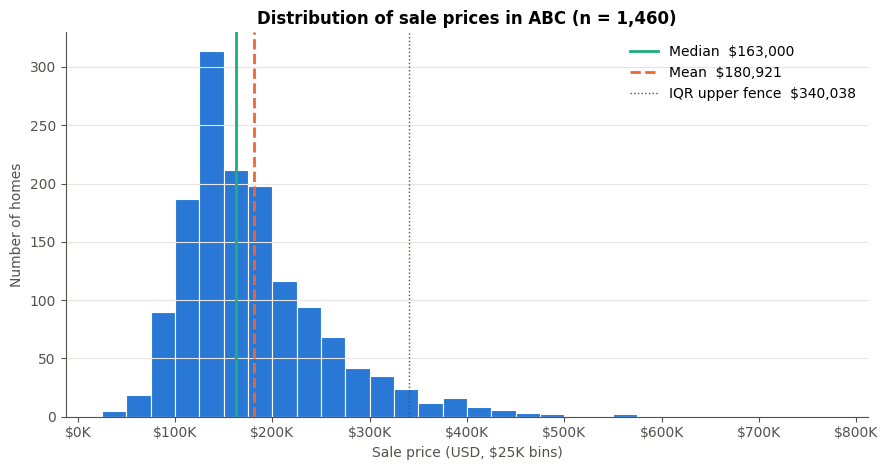

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.8))
bins = np.arange(25_000, 775_001, 25_000)
ax.hist(price, bins=bins, color=BLUE, edgecolor='white', linewidth=0.8)
ax.axvline(median, color=AQUA, lw=2, label=f'Median  ${median:,.0f}')
ax.axvline(mean, color=ORANGE, lw=2, ls='--', label=f'Mean  ${mean:,.0f}')
upper_fence = price.quantile(0.75) + 1.5 * (price.quantile(0.75) - price.quantile(0.25))
ax.axvline(upper_fence, color=GREY_TEXT, lw=1, ls=':', label=f'IQR upper fence  ${upper_fence:,.0f}')
ax.xaxis.set_major_formatter(usd)
ax.set_xlabel('Sale price (USD, $25K bins)')
ax.set_ylabel('Number of homes')
ax.set_title('Distribution of sale prices in ABC (n = 1,460)')
ax.grid(axis='x', visible=False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig('figures/fig1_price_histogram.png', dpi=200, bbox_inches='tight')
plt.show()

The distribution has a single peak around \$125,000–\$175,000 and a long right tail that runs out to \$755,000.
Very few homes sell below \$75,000, and the tail beyond the fence (\$340,000) is thin but long.
This shape is typical of house prices: there is a floor on what a habitable home costs, but no ceiling.

A log scale is the standard way to view prices like these. On the log scale the distribution is close to symmetric
(skewness 0.12), which is why Section 6 models the logarithm of price.

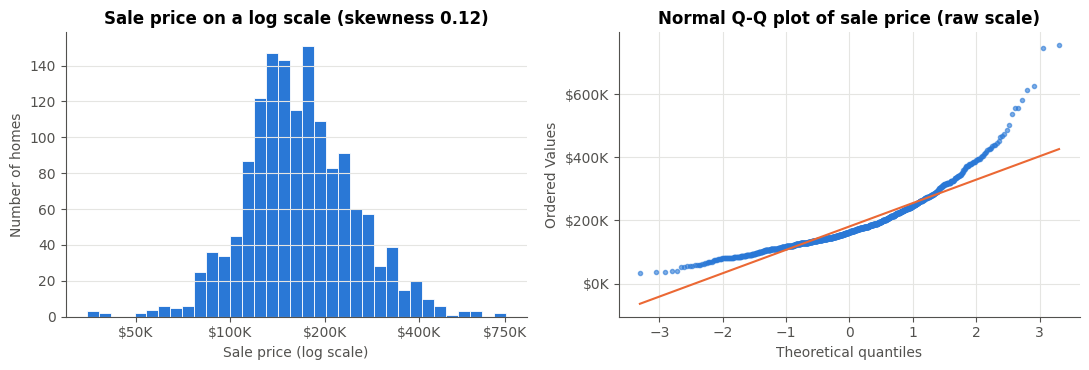

Shapiro-Wilk, raw price : ShapiroResult(statistic=np.float64(0.8696714665902145), pvalue=np.float64(3.2061412312021656e-33))
Shapiro-Wilk, log price : ShapiroResult(statistic=np.float64(0.9912067503807811), pvalue=np.float64(1.1490615527264654e-07))


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
log_price = np.log(price)
axes[0].hist(log_price, bins=35, color=BLUE, edgecolor='white', linewidth=0.6)
ticks = [50_000, 100_000, 200_000, 400_000, 750_000]
axes[0].set_xticks(np.log(ticks), [f'${t/1000:.0f}K' for t in ticks])
axes[0].set_title(f'Sale price on a log scale (skewness {log_price.skew():.2f})')
axes[0].set_xlabel('Sale price (log scale)'); axes[0].set_ylabel('Number of homes')
axes[0].grid(axis='x', visible=False)

stats.probplot(price, dist='norm', plot=axes[1])
axes[1].get_lines()[0].set(color=BLUE, markersize=3, alpha=0.6)
axes[1].get_lines()[1].set(color=ORANGE)
axes[1].yaxis.set_major_formatter(usd)
axes[1].set_title('Normal Q-Q plot of sale price (raw scale)')
fig.tight_layout()
fig.savefig('figures/fig2_log_price_qq.png', dpi=200, bbox_inches='tight')
plt.show()

print('Shapiro-Wilk, raw price :', stats.shapiro(price))
print('Shapiro-Wilk, log price :', stats.shapiro(log_price))

The Q-Q plot bends sharply upward on the right: the most expensive homes are far more expensive than a normal
distribution would predict. Shapiro-Wilk rejects normality on both scales (with 1,460 homes even small departures
are significant), but the log scale is far closer to normal.

## 5. Question 3 - Outliers and how to handle them

I use three standard rules on `SalePrice`:

- **IQR rule (Tukey fences):** below Q1 − 1.5·IQR or above Q3 + 1.5·IQR.
- **Extreme IQR rule:** beyond Q1 − 3·IQR or Q3 + 3·IQR.
- **z-score rule:** more than 3 standard deviations from the mean.

Then I check *bivariate* outliers: homes whose price is out of line with their size. A home can be an
ordinary price and still be an outlier if it is huge but sold cheaply.

In [30]:
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
fences = {'Lower fence (1.5 IQR)': q1 - 1.5 * iqr, 'Upper fence (1.5 IQR)': q3 + 1.5 * iqr,
          'Upper extreme fence (3 IQR)': q3 + 3 * iqr}
z = (price - mean) / sd

flags = pd.DataFrame({
    'IQR rule (1.5)': (price < fences['Lower fence (1.5 IQR)']) | (price > fences['Upper fence (1.5 IQR)']),
    'Extreme IQR rule (3)': (price < q1 - 3 * iqr) | (price > fences['Upper extreme fence (3 IQR)']),
    'z-score > 3': z.abs() > 3,
})
print(f'Q1 = ${q1:,.0f}   Q3 = ${q3:,.0f}   IQR = ${iqr:,.0f}')
for k, v in fences.items():
    print(f'{k:28s} ${v:,.0f}')
summary = pd.DataFrame({'High outliers': flags[price > median].sum(),
                        'Low outliers': flags[price <= median].sum()})
summary['Share of homes (%)'] = (summary.sum(axis=1) / n * 100)
summary

Q1 = $129,975   Q3 = $214,000   IQR = $84,025
Lower fence (1.5 IQR)        $3,938
Upper fence (1.5 IQR)        $340,038
Upper extreme fence (3 IQR)  $466,075


,High outliers,Low outliers,Share of homes (%)
IQR rule (1.5),61,0,4.18
Extreme IQR rule (3),12,0,0.82
z-score > 3,22,0,1.51


All flagged homes are on the **high side**. The lower fence is \$3,938, below the cheapest sale (\$34,900), so no
home is a low outlier by the IQR rule. **61 homes (4.2%)** sell above the upper fence of \$340,038; 12 of them are
"extreme" (above \$466,075), and 22 are more than 3 SD above the mean (above \$419,000).

The key question is whether these are errors or real sales. The table below compares the outliers with the other homes.

In [31]:
homes['PriceOutlier'] = flags['IQR rule (1.5)']
compare_cols = ['SalePrice', 'OverallQual', 'LivArea', 'PricePerSqFt', 'GarageCars', 'FullBath', 'TotalRooms', 'YearBuilt']
profile = homes.groupby('PriceOutlier')[compare_cols].median().T
profile.columns = ['Other homes (median)', 'High-price outliers (median)']
print(f"Outliers rated quality 8 or higher: {(homes.loc[homes.PriceOutlier, 'OverallQual'] >= 8).mean() * 100:.0f}%")
print(f"Outliers built 1995 or later     : {(homes.loc[homes.PriceOutlier, 'YearBuilt'] >= 1995).mean() * 100:.0f}%")
profile

Outliers rated quality 8 or higher: 95%
Outliers built 1995 or later     : 84%


,Other homes (median),High-price outliers (median)
SalePrice,"159,500.00","394,617.00"
OverallQual,6.00,9.00
LivArea,"1,434.00","2,364.00"
PricePerSqFt,119.27,182.06
GarageCars,2.00,3.00
FullBath,2.00,2.00
TotalRooms,6.00,9.00
YearBuilt,"1,971.00","2,006.00"


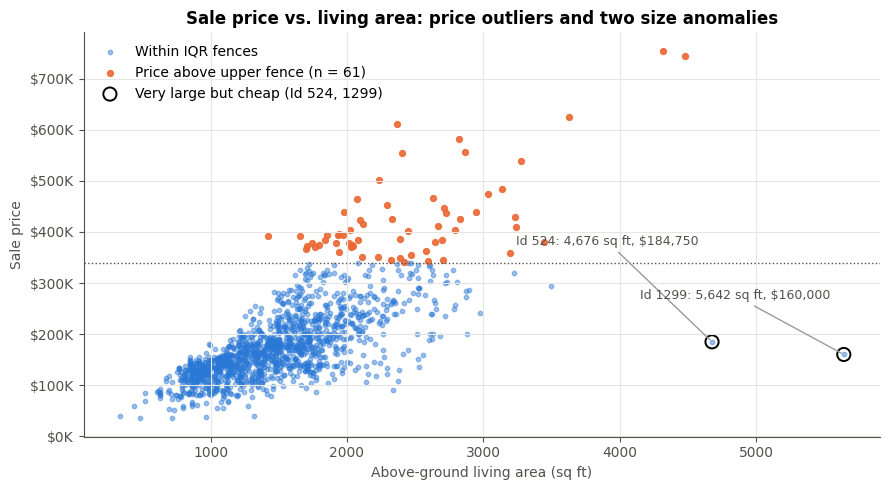

,Id,OverallQual,LivArea,LotArea,YearBuilt,YrSold,SalePrice,PricePerSqFt
523,524,10,4676,"40,094.00",2007,2007,184750,39.51
1298,1299,10,5642,"63,887.00",2008,2008,160000,28.36


In [32]:
fig, ax = plt.subplots(figsize=(9, 5))
normal = homes[~homes.PriceOutlier]
out = homes[homes.PriceOutlier]
ax.scatter(normal.LivArea, normal.SalePrice, s=10, color=BLUE, alpha=0.45, label='Within IQR fences')
ax.scatter(out.LivArea, out.SalePrice, s=18, color=ORANGE, alpha=0.9, label=f'Price above upper fence (n = {len(out)})')
odd = homes[(homes.LivArea > 4500) & (homes.SalePrice < 300_000)]
ax.scatter(odd.LivArea, odd.SalePrice, s=90, facecolors='none', edgecolors='black', lw=1.4,
           label='Very large but cheap (Id ' + ', '.join(map(str, odd.Id)) + ')')
for (_, r), dy in zip(odd.iterrows(), [70, 40]):
    ax.annotate(f'Id {r.Id}: {r.LivArea:,.0f} sq ft, ${r.SalePrice:,.0f}', (r.LivArea, r.SalePrice),
                xytext=(-10, dy), textcoords='offset points', ha='right', fontsize=9, color=GREY_TEXT,
                arrowprops=dict(arrowstyle='-', color=GREY))
ax.axhline(fences['Upper fence (1.5 IQR)'], color=GREY_TEXT, lw=1, ls=':')
ax.yaxis.set_major_formatter(usd)
ax.set_xlabel('Above-ground living area (sq ft)')
ax.set_ylabel('Sale price')
ax.set_title('Sale price vs. living area: price outliers and two size anomalies')
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
fig.savefig('figures/fig3_outliers_scatter.png', dpi=200, bbox_inches='tight')
plt.show()

odd[['Id', 'OverallQual', 'LivArea', 'LotArea', 'YearBuilt', 'YrSold', 'SalePrice', 'PricePerSqFt']]

**What the outliers are.**

1. **The 61 high-price homes are real luxury sales, not errors.** 95% are rated quality 8 or higher (median 9 vs. 6),
   they are about 65% larger (2,364 vs. 1,434 sq ft), have 3-car garages, and the median one was built in 2006.
   They also cost more per square foot (\$182 vs. \$119), which fits higher-end construction. Their prices follow
   from their features, so they form a genuine upper segment of the market.
2. **Two homes (Id 524 and 1299) are anomalies of a different kind.** They are the two largest homes in the data
   (4,676 and 5,642 sq ft), rated quality 10, built new in 2007–2008, yet sold for only \$184,750 and \$160,000,
   which is \$28–\$40 per square foot against a market median of about \$120. The price rules do *not* catch them,
   because their prices are ordinary. The compiler of the original data (De Cock, 2011) flags these very large homes
   as partial sales that likely do not represent actual market values.
3. **No low-price outliers.** The cheapest homes (\$35,000–\$52,000) are low quality (ratings 1–4), mostly without
   central air, which explains their prices.

**How I handle them.**

- **Keep the 61 high-price homes.** Deleting legitimate sales would understate what the market costs and remove the
  segment some clients may want. Instead, I *limit their influence*: report the **median** and percentiles alongside
  the mean, and model **log(price)**, which pulls the long tail in.
- **Exclude Id 524 and 1299 from the price model** (Section 6), because they are not arm's-length market prices
  and would distort the size–price relationship. I show the model with and without them so the effect is visible.
- **Sensitivity check:** the table below shows how much the headline numbers move under each treatment.

In [33]:
def describe(s):
    return pd.Series({'Homes': s.size, 'Mean': s.mean(), 'SD': s.std(), 'Median': s.median(), 'Skewness': s.skew()})

capped = price.clip(upper=fences['Upper fence (1.5 IQR)'])
sens = pd.DataFrame({
    'All homes (reported)': describe(price),
    'Excluding Id 524 & 1299': describe(price[~homes.Id.isin([524, 1299])]),
    'Excluding 61 IQR outliers': describe(price[~homes.PriceOutlier]),
    'Capped at upper fence (winsorized)': describe(capped),
    'Log scale, back-transformed (geometric mean)': pd.Series({'Homes': n, 'Mean': np.exp(log_price.mean()),
                                                               'SD': np.nan, 'Median': np.exp(log_price.median()),
                                                               'Skewness': log_price.skew()}),
}).T
sens

,Homes,Mean,SD,Median,Skewness
All homes (reported),"1,460.00","180,921.20","79,442.50","163,000.00",1.88
Excluding Id 524 & 1299,"1,458.00","180,932.92","79,495.06","163,000.00",1.88
Excluding 61 IQR outliers,"1,399.00","170,237.13","59,230.13","159,500.00",0.68
Capped at upper fence (winsorized),"1,460.00","177,331.53","67,205.84","163,000.00",0.80
"Log scale, back-transformed (geometric mean)","1,460.00","166,716.64",NaN,"163,000.00",0.12


Removing the 61 high-price homes lowers the mean by about \$10,700 (to \$170,237) and the SD by 25% (to \$59,230),
but the **median barely moves** (\$163,000 → \$159,500). This is the main reason the median is the better figure
to quote to clients. The two size anomalies have almost no effect on the price summaries; they matter only for the
size–price relationship.

## 6. What drives price? (supporting analysis for buyers)

In [34]:
num_cols = ['OverallQual', 'LivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', 'FullBath', 'TotalRooms',
            'YearBuilt', '1stFlrSF', 'LotFrontage', '2ndFlrSF', 'LotArea', 'CentralAir', 'OverallCond', 'YrSold']
corr = pd.DataFrame({
    'Pearson r': homes[num_cols].corrwith(homes.SalePrice),
    'Spearman rho': homes[num_cols].corrwith(homes.SalePrice, method='spearman'),
    'Non-missing': homes[num_cols].notna().sum(),
}).sort_values('Spearman rho', ascending=False)
corr

,Pearson r,Spearman rho,Non-missing
OverallQual,0.79,0.81,1460
LivArea,0.72,0.74,1460
GarageCars,0.64,0.69,1460
YearBuilt,0.52,0.65,1460
GarageArea,0.62,0.65,1460
FullBath,0.56,0.64,1460
TotalBsmtSF,0.64,0.61,913
1stFlrSF,0.61,0.58,1460
TotalRooms,0.53,0.53,1460
LotArea,0.27,0.46,1341


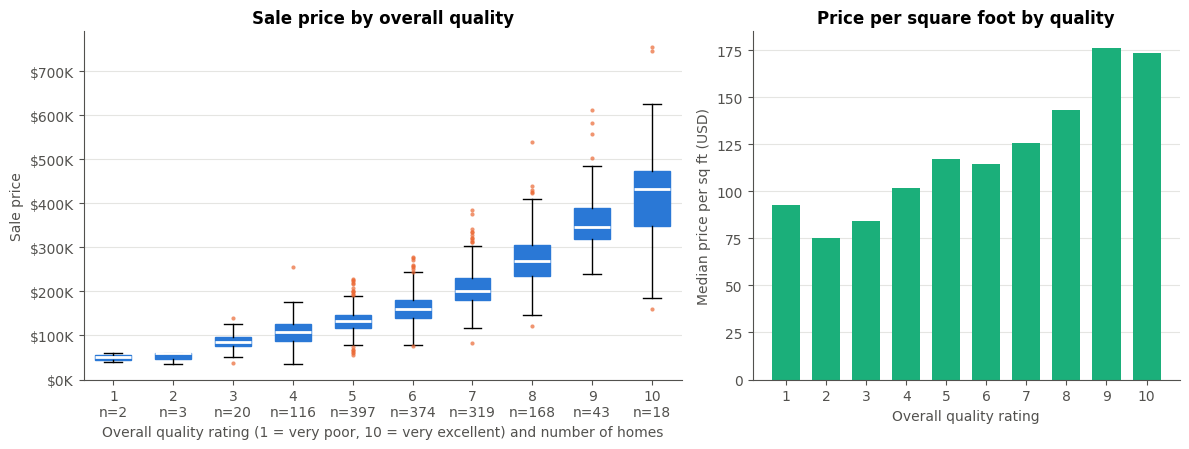

,Homes,MedianPrice,MedianLivArea,MedianPricePerSqFt
OverallQual,,,,
1,2,"50,150.00",619.00,92.57
2,3,"60,000.00",480.00,75.00
3,20,"86,250.00","1,040.00",84.31
4,116,"108,000.00","1,043.50",101.94
5,397,"133,000.00","1,142.00",117.34
6,374,"160,000.00","1,435.50",114.64
7,319,"200,141.00","1,656.00",125.60
8,168,"269,750.00","1,813.50",143.19
9,43,"345,000.00","1,922.00",176.22


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.4, 1]})
q_levels = sorted(homes.OverallQual.unique())
data = [homes.loc[homes.OverallQual == q, 'SalePrice'] for q in q_levels]
bp = axes[0].boxplot(data, positions=q_levels, widths=0.6, patch_artist=True, showfliers=True,
                     medianprops=dict(color='white', lw=2),
                     flierprops=dict(marker='o', markersize=3, markerfacecolor=ORANGE, markeredgecolor='none', alpha=0.7))
for b in bp['boxes']:
    b.set(facecolor=BLUE, edgecolor=BLUE)
axes[0].set_xticks(q_levels, [f'{q}\nn={len(d)}' for q, d in zip(q_levels, data)])
axes[0].set_ylim(0, 790_000)
axes[0].yaxis.set_major_formatter(usd)
axes[0].set_xlabel('Overall quality rating (1 = very poor, 10 = very excellent) and number of homes')
axes[0].set_ylabel('Sale price')
axes[0].set_title('Sale price by overall quality')
axes[0].grid(axis='x', visible=False)

med_q = homes.groupby('OverallQual')['PricePerSqFt'].median()
axes[1].set_axisbelow(True)
axes[1].bar(med_q.index, med_q.values, color=AQUA, width=0.7)
axes[1].set_xticks(q_levels)
axes[1].set_xlabel('Overall quality rating')
axes[1].set_ylabel('Median price per sq ft (USD)')
axes[1].set_title('Price per square foot by quality')
axes[1].grid(axis='x', visible=False)
fig.tight_layout()
fig.savefig('figures/fig4_quality.png', dpi=200, bbox_inches='tight')
plt.show()

homes.groupby('OverallQual').agg(Homes=('SalePrice', 'size'), MedianPrice=('SalePrice', 'median'),
                                 MedianLivArea=('LivArea', 'median'), MedianPricePerSqFt=('PricePerSqFt', 'median'))

**Overall quality is the single strongest driver of price** (Spearman ρ ≈ 0.81). Each step up the quality scale
raises the median price, and the jumps get larger at the top: from rating 7 to 8 the median rises about \$70,000.
Quality also raises the price *per square foot*, so higher-quality homes are not just bigger, they cost more per foot.

To separate the effects of quality, size, age and features, I fit an OLS regression on **log(price)**. Each coefficient
×100 is approximately the % change in price for a one-unit change, holding the other variables fixed.
Columns with large missing shares (`TotalBsmtSF`, `LotFrontage`, `LotArea`) are left out (see Section 2).

In [36]:
formula = ('np.log(SalePrice) ~ OverallQual + I(LivArea/100) + YearBuilt + GarageCars + FullBath '
           '+ CentralAir + OverallCond + C(YrSold)')
model_all = smf.ols(formula, data=homes).fit()
clean = homes[~homes.Id.isin([524, 1299])].copy()
model = smf.ols(formula, data=clean).fit()

comp = pd.DataFrame({'All 1,460 homes': model_all.params, 'Excl. Id 524 & 1299': model.params,
                     'p-value (excl.)': model.pvalues}).drop(index='Intercept')
comp['% effect (excl.)'] = (np.exp(comp['Excl. Id 524 & 1299']) - 1) * 100
print(f'R-squared: all homes {model_all.rsquared:.3f} | excluding the two anomalies {model.rsquared:.3f}')
comp

R-squared: all homes 0.826 | excluding the two anomalies 0.850


,"All 1,460 homes",Excl. Id 524 & 1299,p-value (excl.),% effect (excl.)
C(YrSold)[T.2007],-0.01,-0.00,0.84,-0.25
C(YrSold)[T.2008],-0.01,0.00,0.95,0.09
C(YrSold)[T.2009],-0.02,-0.02,0.19,-1.58
C(YrSold)[T.2010],-0.01,-0.01,0.65,-0.66
OverallQual,0.10,0.10,0.00,10.14
I(LivArea / 100),0.03,0.03,0.00,3.54
YearBuilt,0.00,0.00,0.00,0.36
GarageCars,0.09,0.08,0.00,8.65
FullBath,-0.01,-0.03,0.00,-3.38
CentralAir,0.11,0.11,0.00,11.27


In [37]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:      np.log(SalePrice)   R-squared:                       0.850
Model:                            OLS   Adj. R-squared:                  0.849
Method:                 Least Squares   F-statistic:                     743.6
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        04:22:20   Log-Likelihood:                 650.62
No. Observations:                1458   AIC:                            -1277.
Df Residuals:                    1446   BIC:                            -1214.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             3.3885      0.42

Excluding the two anomalous sales raises R² from 0.826 to 0.850, confirming that they were distorting the fit.
In the cleaned model, holding the other features constant:

- **+1 quality point → about +10% in price**, the largest per-unit effect.
- **+100 sq ft of living area → about +3.5%.**
- **Each additional garage space → about +9%.**
- **Central air → about +11%;** homes without it are concentrated at the bottom of the market.
- **Each year newer → about +0.4%**, so a home built 20 years later is about 7% more expensive, other things equal.
- **Better condition (`OverallCond`) → about +5% per point.**
- **Full bathrooms → about −3% each**, *given the same floor area*. This is not a penalty for bathrooms (they
  correlate positively with price, ρ = 0.64); more bathrooms in the same space means smaller rooms elsewhere,
  and bathrooms overlap heavily with size and quality.
- **Sale year has no significant effect** once features are controlled for (see Section 7).

The model explains 85% of the variation in log price, so it can serve as a **"fair-price" benchmark** for a listing
(Section 8).

## 7. Have prices changed over time?

In [38]:
by_year = homes.groupby('YrSold')['SalePrice'].agg(Homes='size', Median='median', Mean='mean',
                                                    Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75))
kw = stats.kruskal(*[g.SalePrice for _, g in homes.groupby('YrSold')])
print(f'Kruskal-Wallis across sale years: H = {kw.statistic:.2f}, p = {kw.pvalue:.3f}')
slope, intercept = np.polyfit(homes.YrSold, homes.SalePrice, 1)
print(f'Linear trend (np.polyfit): {slope:+,.0f} USD per year')
by_year

Kruskal-Wallis across sale years: H = 1.65, p = 0.801
Linear trend (np.polyfit): -1,730 USD per year


,Homes,Median,Mean,Q1,Q3
YrSold,,,,,
2006,314,"163,995.00","182,549.46","131,375.00","218,782.50"
2007,329,"167,000.00","186,063.15","129,900.00","219,500.00"
2008,304,"164,000.00","177,360.84","131,250.00","207,000.00"
2009,338,"162,000.00","179,432.10","125,250.00","212,750.00"
2010,175,"155,000.00","177,393.67","128,100.00","213,250.00"


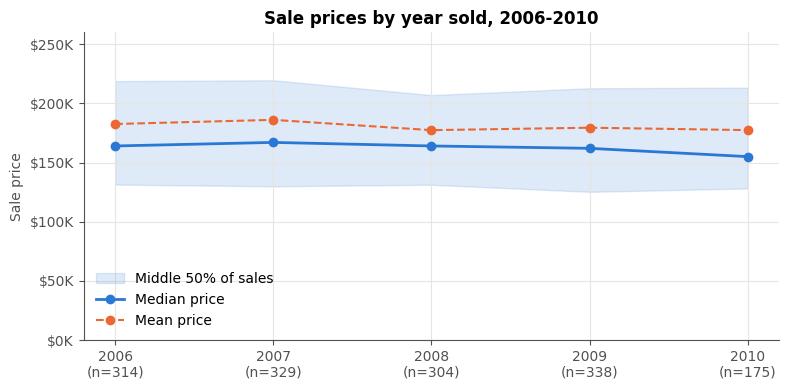

In [39]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(by_year.index, by_year.Q1, by_year.Q3, color=BLUE, alpha=0.15, label='Middle 50% of sales')
ax.plot(by_year.index, by_year.Median, color=BLUE, marker='o', lw=2, label='Median price')
ax.plot(by_year.index, by_year.Mean, color=ORANGE, marker='o', lw=1.5, ls='--', label='Mean price')
ax.set_xticks(by_year.index, [f'{y}\n(n={c})' for y, c in by_year.Homes.items()])
ax.yaxis.set_major_formatter(usd)
ax.set_ylim(0, 260_000)
ax.set_ylabel('Sale price')
ax.set_title('Sale prices by year sold, 2006-2010')
ax.legend(frameon=False, loc='lower left')
fig.tight_layout()
fig.savefig('figures/fig5_price_by_year.png', dpi=200, bbox_inches='tight')
plt.show()

Prices in ABC were **flat from 2006 to 2010**: the median stayed between \$155,000 and \$167,000, and the difference
across years is not statistically significant (Kruskal-Wallis p ≈ 0.80). The 2010 figure covers only part of the year
(175 sales vs. 300+ in other years), so its slightly lower median should not be read as a decline.
There is no evidence of a rising market that would reward buying immediately, or of a falling one that would reward waiting.

## 8. Budget guide and value check for clients

In [40]:
bands = [0, 130_000, 163_000, 214_000, 340_000, np.inf]
labels = ['Entry (< $130K)', 'Lower-middle ($130K-163K)', 'Upper-middle ($163K-214K)',
          'Upper ($214K-340K)', 'Luxury (> $340K)']
homes['Budget band'] = pd.cut(homes.SalePrice, bins=bands, labels=labels, right=False)
budget = homes.groupby('Budget band', observed=True).agg(
    Homes=('SalePrice', 'size'),
    MedianPrice=('SalePrice', 'median'),
    MedianLivArea=('LivArea', 'median'),
    MedianPricePerSqFt=('PricePerSqFt', 'median'),
    MedianQuality=('OverallQual', 'median'),
    MedianYearBuilt=('YearBuilt', 'median'),
    MedianGarageCars=('GarageCars', 'median'),
    PctCentralAir=('CentralAir', lambda s: s.mean() * 100),
    PctTwoPlusFullBath=('FullBath', lambda s: (s >= 2).mean() * 100),
    MostCommonStyle=('HouseStyle', lambda s: s.mode().iat[0]),
)
budget['Share of homes (%)'] = budget.Homes / n * 100
budget

,Homes,MedianPrice,MedianLivArea,MedianPricePerSqFt,MedianQuality,MedianYearBuilt,MedianGarageCars,PctCentralAir,PctTwoPlusFullBath,MostCommonStyle,Share of homes (%)
Budget band,,,,,,,,,,,
Entry (< $130K),365,"110,000.00","1,040.00",100.18,5.00,"1,949.00",1.00,80.00,16.44,1Story,25.00
Lower-middle ($130K-163K),363,"144,000.00","1,229.00",119.05,5.00,"1,963.00",2.00,95.87,30.58,1Story,24.86
Upper-middle ($163K-214K),365,"182,000.00","1,516.00",119.54,6.00,"1,994.00",2.00,98.90,79.45,1Story,25.00
Upper ($214K-340K),304,"251,500.00","1,883.00",133.39,7.00,"2,001.00",2.00,99.01,92.43,2Story,20.82
Luxury (> $340K),63,"394,432.00","2,392.00",177.17,9.00,"2,005.00",3.00,100.00,93.65,1Story,4.32


The bands follow the quartiles (\$130K, \$163K, \$214K) and the outlier fence (\$340K, rounded), so each band
corresponds to a real segment of the market. Moving from the entry band to the upper-middle band (a median of
\$110K to \$182K) typically adds about 480 sq ft, one quality point, a second garage space, a second full bathroom
(16% → 79% of homes), and 45 years of newer construction (median built 1949 vs. 1994). The two middle bands cost about
the same per square foot (\$119–\$120), so the step between them buys space and newer construction at a constant rate.

In [41]:
clean['Predicted'] = np.exp(model.fittedvalues) * np.mean(np.exp(model.resid))   # smearing correction
clean['Price vs. predicted (%)'] = (clean.SalePrice / clean.Predicted - 1) * 100
under = clean['Price vs. predicted (%)'] <= -15
over = clean['Price vs. predicted (%)'] >= 15
print(f'Sold >=15% below the model price: {under.sum()} homes ({under.mean()*100:.1f}%)')
print(f'Sold >=15% above the model price: {over.sum()} homes ({over.mean()*100:.1f}%)')
print(f'Typical model error (median absolute %): {clean["Price vs. predicted (%)"].abs().median():.1f}%')

clean.loc[under].groupby('OverallCond').size().rename('Homes sold >=15% below model, by condition').to_frame().T

Sold >=15% below the model price: 199 homes (13.6%)
Sold >=15% above the model price: 196 homes (13.4%)
Typical model error (median absolute %): 9.3%


OverallCond,2,3,4,5,6,7,8,9
"Homes sold >=15% below model, by condition",1,9,9,111,28,21,15,5


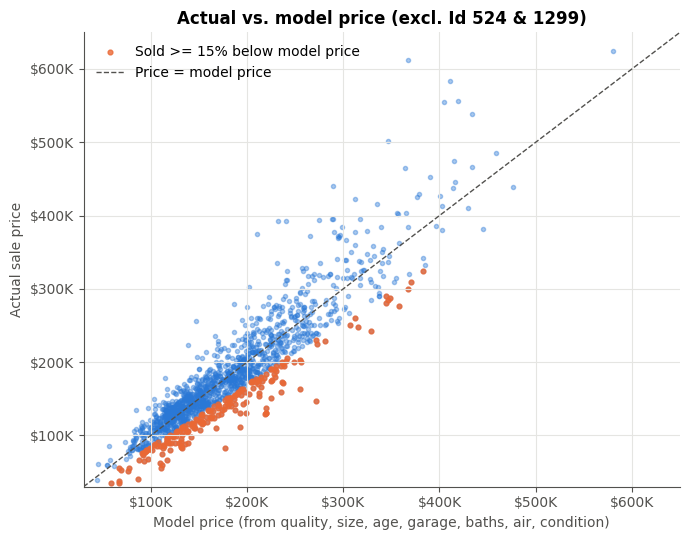

In [42]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(clean.Predicted, clean.SalePrice, s=9, color=BLUE, alpha=0.4)
ax.scatter(clean.loc[under, 'Predicted'], clean.loc[under, 'SalePrice'], s=12, color=ORANGE, alpha=0.8,
           label='Sold >= 15% below model price')
lim = [30_000, 650_000]
ax.plot(lim, lim, color=GREY_TEXT, lw=1, ls='--', label='Price = model price')
ax.set_xlim(lim); ax.set_ylim(lim)
ax.xaxis.set_major_formatter(usd); ax.yaxis.set_major_formatter(usd)
ax.set_xlabel('Model price (from quality, size, age, garage, baths, air, condition)')
ax.set_ylabel('Actual sale price')
ax.set_title('Actual vs. model price (excl. Id 524 & 1299)')
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
fig.savefig('figures/fig6_actual_vs_model.png', dpi=200, bbox_inches='tight')
plt.show()

Half of the homes sell within about 9% of the model price. About 14% sell 15% or more below it (and a similar share
15% or more above it). Most of the below-model sales are in average condition (rating 5), so a low price is not just
a sign of a run-down house. These are the candidates a buyer should look at closely: some may be genuine bargains, others will have a problem the 17 attributes
do not capture (location within the neighborhood, a needed repair, an unusual sale). The model is a screening tool,
not an appraisal.

## 9. Summary of results

In [43]:
print(f"Q1  Mean sale price ${mean:,.0f}; standard deviation ${sd:,.0f}; median ${median:,.0f}.")
print(f"Q2  Right-skewed distribution (skewness {price.skew():.2f}); log price is close to symmetric ({log_price.skew():.2f}).")
print(f"Q3  {flags['IQR rule (1.5)'].sum()} high-price IQR outliers (> ${fences['Upper fence (1.5 IQR)']:,.0f}), no low outliers;"
      f" kept as real luxury sales. Id 524 & 1299 excluded from the model as non-market sales.")
print(f"    Without the 61 outliers: mean ${price[~homes.PriceOutlier].mean():,.0f}, median ${price[~homes.PriceOutlier].median():,.0f}.")
print(f"Model (log price, n = {int(model.nobs)}): R-squared = {model.rsquared:.2f}; +1 quality point = "
      f"{(np.exp(model.params['OverallQual'])-1)*100:+.0f}%, +100 sq ft = {(np.exp(model.params['I(LivArea / 100)'])-1)*100:+.1f}%.")
print(f"Prices flat 2006-2010 (Kruskal-Wallis p = {kw.pvalue:.2f}).")

Q1  Mean sale price $180,921; standard deviation $79,443; median $163,000.
Q2  Right-skewed distribution (skewness 1.88); log price is close to symmetric (0.12).
Q3  61 high-price IQR outliers (> $340,038), no low outliers; kept as real luxury sales. Id 524 & 1299 excluded from the model as non-market sales.
    Without the 61 outliers: mean $170,237, median $159,500.
Model (log price, n = 1458): R-squared = 0.85; +1 quality point = +10%, +100 sq ft = +3.5%.
Prices flat 2006-2010 (Kruskal-Wallis p = 0.80).


In [44]:
# Save the cleaned analysis table alongside the notebook
homes.drop(columns=['Budget band']).to_csv('HousingPrices_analysis.csv', index=False)
print('Saved HousingPrices_analysis.csv and figures/:', sorted(os.listdir('figures')))

Saved HousingPrices_analysis.csv and figures/: ['fig1_price_histogram.png', 'fig2_log_price_qq.png', 'fig3_outliers_scatter.png', 'fig4_quality.png', 'fig5_price_by_year.png', 'fig6_actual_vs_model.png']
